In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

### Initialization

In [3]:
DATA = "B"

### Load Profile

Index(['load'], dtype='object')


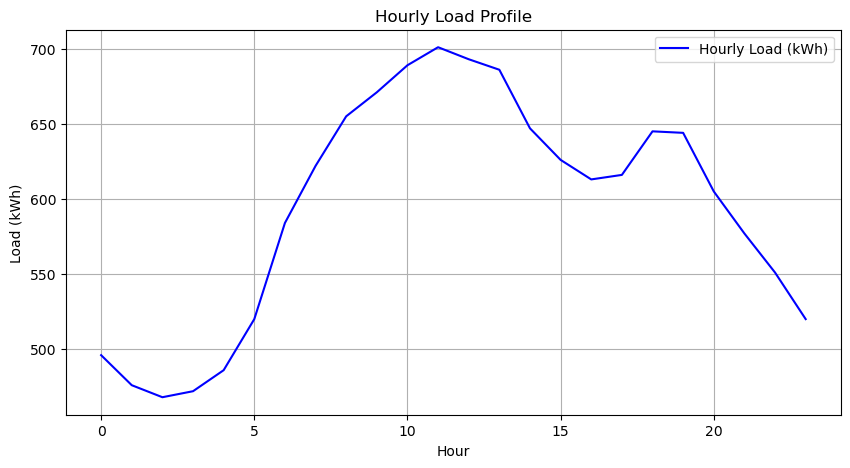

In [4]:
hourly_load = pd.read_csv(f"Data/Data{DATA}_hourlyload.csv", index_col=0, sep=";")

print(hourly_load.columns)

# Plot load profile 
plt.figure(figsize=(10, 5))
plt.plot(hourly_load.index, hourly_load['load'], label='Hourly Load (kWh)', color='blue')
plt.title('Hourly Load Profile')
plt.xlabel('Hour')
plt.ylabel('Load (kWh)')
plt.grid(True)
plt.legend()
plt.show()

### Dispatchable generator costs

Index(['a1', 'a2', 'pmin', 'pmax'], dtype='object')


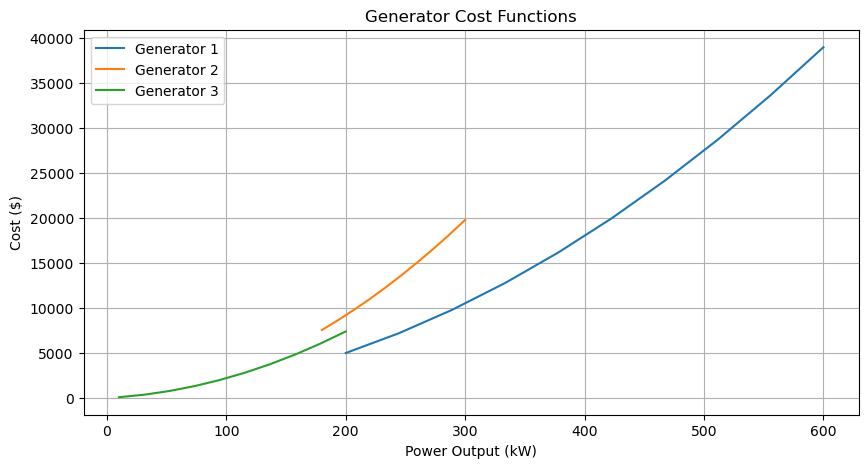

In [6]:
gen_params = pd.read_csv(f"Data/Data{DATA}_generatorparams.csv", index_col=0, sep=";")

print(gen_params.columns)

# Plot generator cost functions
plt.figure(figsize=(10,5))
for gen in gen_params.index:
    a1 = gen_params.loc[gen, 'a1']
    a2 = gen_params.loc[gen, 'a2']
    p = np.linspace(gen_params.loc[gen, 'pmin'], gen_params.loc[gen, 'pmax'], 10)
    cost = a2 * p**2 + a1 * p
    plt.plot(p, cost, label=f'Generator {gen}')
plt.title('Generator Cost Functions')
plt.xlabel('Power Output (kW)')
plt.ylabel('Cost ($)')
plt.grid(True)
plt.legend()
plt.savefig(f"Data/Figures/Generator_Cost_Functions_Data{DATA}.png")
plt.show()

### Non-dispatchable generation

Index(['hour', 'generation wind', 'probability wind', 'generation solar',
       'probability solar'],
      dtype='object')


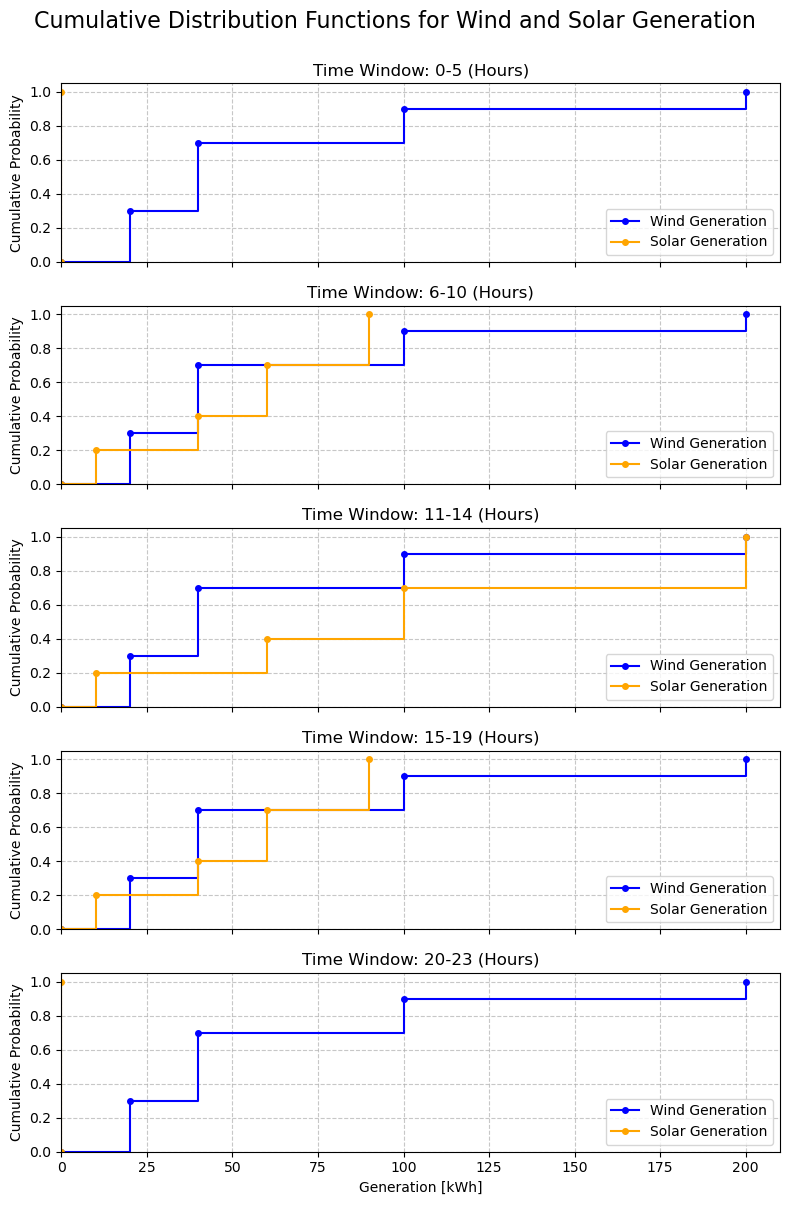

In [8]:
non_dis_gen = pd.read_csv(f"Data/Data{DATA}_nondispgeneration.csv", sep=";")

print(non_dis_gen.columns)

# Time windows
time_windows = ['0-5', '6-10', '11-14', '15-19', '20-23']

# Set up the figure and subplots (5 rows, 1 column)
fig, axes = plt.subplots(nrows=len(time_windows), ncols=1, figsize=(8, 12), sharex=True)
fig.suptitle('Cumulative Distribution Functions for Wind and Solar Generation', fontsize=16, y=1.0)
plt.subplots_adjust(hspace=0.4) # Add space between subplots

# Define a function to calculate and plot CDF for a resource
def plot_cdf(ax, data, gen_col, prob_col, label, color):
    # Select, convert, and sort the data
    cdf_data = data[[gen_col, prob_col]].copy()
    cdf_data.columns = ['generation', 'probability']
    cdf_data['generation'] = pd.to_numeric(cdf_data['generation'])
    cdf_data['probability'] = pd.to_numeric(cdf_data['probability'])
    
    # Filter out rows where probability is 0 and sort
    cdf_data = cdf_data[cdf_data['probability'] > 0].sort_values(by='generation').reset_index(drop=True)

    # Calculate CDF
    cdf_data['cdf'] = cdf_data['probability'].cumsum()

    # Prepare plotting points (start at 0, 0)
    x_cdf = [0] + cdf_data['generation'].tolist()
    y_cdf = [0] + cdf_data['cdf'].tolist()

    # Plot
    ax.step(x_cdf, y_cdf, where='post', marker='o', linestyle='-', label=label, color=color, markersize=4)

# Loop through each time window and create a subplot
for i, window in enumerate(time_windows):
    ax = axes[i]
    window_data = non_dis_gen[non_dis_gen['hour'] == window].copy()

    # Plot Wind CDF
    plot_cdf(ax, window_data, 'generation wind', 'probability wind', 'Wind Generation', 'blue')

    # Plot Solar CDF
    plot_cdf(ax, window_data, 'generation solar', 'probability solar', 'Solar Generation', 'orange')
    
    # Set subplot details
    ax.set_title(f'Time Window: {window} (Hours)')
    ax.set_ylabel('Cumulative Probability')
    ax.set_ylim(0, 1.05)
    ax.set_xlim(0, 210)
    ax.set_yticks([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.grid(axis='both', linestyle='--', alpha=0.7)
    ax.legend(loc='lower right')

# Set a common X label for the bottom-most subplot
axes[-1].set_xlabel('Generation [kWh]')

plt.tight_layout()
plt.savefig(f"Data/Figures/Wind_Solar_CDFs_Data{DATA}.png")
plt.show()


### Summary
Load Profile shows peaks at noon and in the evening as expected.<br><br>
Cost Functions show operation area of dispatchable generators and there respective costs.<br><br>
Cumulative Distribution Functions (CDF) for Wind and Solar for 4 Time Windows.<br>
How to read: Probability that the Wind/Solar produces less or equal the amount of power.<br>
For example: The probability that the Wind in Time Window 0-5 produces less or equal to 100 kWh is 0.9.